# Previsão do consumo elétrico de edifícios universitários

Edifícios: **ABR, C e ICSTM** (componente **elétrica**) \
Anos: **2019 e 2020**. \
Dataset: *University campus buildings electrical and thermal demand and generation* (Zenodo, projeto E-LAND).

## Configuração e carregamento dos dados
Os ficheiros CSV (`UVTgv_<tipo>_<edifício>_2019_2020.csv`, com `TIPO = "elec"` para a componente elétrica) são lidos de `dataset/UVTgv_OD/demand/`, a partir da raiz do repositório. \
Cada um tem 2 colunas (2019 e 2020) com 8760 registos horários. Os dados vão de 1 de janeiro de 2019 a 31 de dezembro de 2020, com registos hora a hora (cada ano começa a 1 de janeiro às 00:00).

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (12, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

EDIFICIOS = ["ABR", "C", "ICSTM"]
TIPO = "elec"          # "elec" (elétrico) ou "heat" (térmico): este notebook analisa a componente elétrica

def nome_ficheiro(tipo, edificio):
    if tipo == "heat" and edificio == "ICSTM":
        return "UVTgv_heat_demand_building_ICSTM_2019.csv"      # no repositório tem outro nome (mas contém 2019 e 2020)
    return f"UVTgv_{tipo}_{edificio}_2019_2020.csv"

# sobe até à raiz do repositório (a pasta que contém "dataset")
RAIZ = Path.cwd()
while not (RAIZ / "dataset").exists():
    RAIZ = RAIZ.parent
PASTA_DADOS = RAIZ / "dataset" / "UVTgv_OD" / "demand"
DIAS = ["Seg", "Ter", "Qua", "Qui", "Sex", "Sáb", "Dom"]

partes = []
for ed in EDIFICIOS:
    df = pd.read_csv(PASTA_DADOS / nome_ficheiro(TIPO, ed), sep=";")
    for col in df.columns:
        ano = int(col[-4:])                        # também funciona com 'elec_ISCTM_2020'
        s = df[col].astype(float)
        horas = pd.date_range(f"{ano}-01-01 00:00", f"{ano}-12-31 23:00", freq="h")
        horas = horas[~((horas.month == 2) & (horas.day == 29))]    # assume-se que o dia 29 de fevereiro não existe
        s.index = horas                                             # 8760 horas em cada ano
        partes.append(pd.DataFrame({"consumo": s, "edificio": ed, "ano": ano}))

d = pd.concat(partes).sort_index(kind="stable")
d["hora"] = d.index.hour
d["dia_semana"] = d.index.dayofweek          # 0 = segunda
d["mes"] = d.index.month
d["fim_semana"] = d["dia_semana"] >= 5
# 2020 é tratado como um ano de 365 dias (sem 29 de fevereiro): dia do ano e hora do ano comparáveis com 2019
d["dia_ano"] = d.index.dayofyear - ((d.index.year == 2020) & (d.index >= "2020-03-01")).astype(int)
d["hora_ano"] = (d["dia_ano"] - 1) * 24 + d["hora"]
anos = [2019, 2020]
d.head()

,consumo,edificio,ano,hora,dia_semana,mes,fim_semana,dia_ano,hora_ano
2019-01-01 00:00:00,44.630080,ABR,2019,0,1,1,False,1,0
2019-01-01 00:00:00,15.042488,C,2019,0,1,1,False,1,0
2019-01-01 00:00:00,18.420000,ICSTM,2019,0,1,1,False,1,0
2019-01-01 01:00:00,45.302036,ABR,2019,1,1,1,False,1,1
2019-01-01 01:00:00,15.309816,C,2019,1,1,1,False,1,1


---
# 4.1. Análise exploratória dos dados

## 4.1.1. Número de registos
Cada ficheiro anual tem 8760 registos horários (365 dias × 24 h), como indica o guião. No total são 3 edifícios × 2 anos × 8760 = **52 560 registos** (17 520 por edifício).

In [2]:
print("Nº total de registos:", len(d))
print(d.groupby(["edificio", "ano"]).size().rename("registos").to_frame().T.to_string(), "\n")


Nº total de registos: 52560
edificio   ABR           C       ICSTM      
ano       2019  2020  2019  2020  2019  2020
registos  8760  8760  8760  8760  8760  8760 



## 4.1.2. Variável de consumo a prever e unidades
- **Variável a prever:** consumo horário de eletricidade de cada edifício.
- **Unidade:** kWh por hora.

## 4.1.3. Distribuição e variabilidade do consumo
Estatísticas descritivas por edifício e ano (inclui o coeficiente de variação, CV, e a assimetria), seguidas do histograma e do diagrama de caixa.

In [3]:
resumo = d.groupby(["edificio", "ano"])["consumo"].describe()
resumo["CV"] = resumo["std"] / resumo["mean"]
resumo["skew"] = d.groupby(["edificio", "ano"])["consumo"].skew()
resumo.round(2)

count   mean    std   min    25%    50%    75%     max    CV  \
edificio ano                                                                   
ABR      2019  8760.0  42.37  26.31  7.11  22.84  36.40  51.78  193.21  0.62   
         2020  8760.0  30.25  14.02  8.73  20.09  27.23  36.63  126.76  0.46   
C        2019  8760.0  26.67  12.35  4.32  18.41  22.17  32.13   94.09  0.46   
         2020  8760.0  19.42  11.16  0.32  10.23  17.05  26.16   66.78  0.57   
ICSTM    2019  8760.0  24.19  16.77  0.00  16.15  20.29  26.82  204.70  0.69   
         2020  8760.0  17.61  24.62  0.00   8.16  14.37  17.78  235.94  1.40   

               skew  
edificio ano         
ABR      2019  1.40  
         2020  1.36  
C        2019  1.60  
         2020  0.96  
ICSTM    2019  3.82  
         2020  4.63

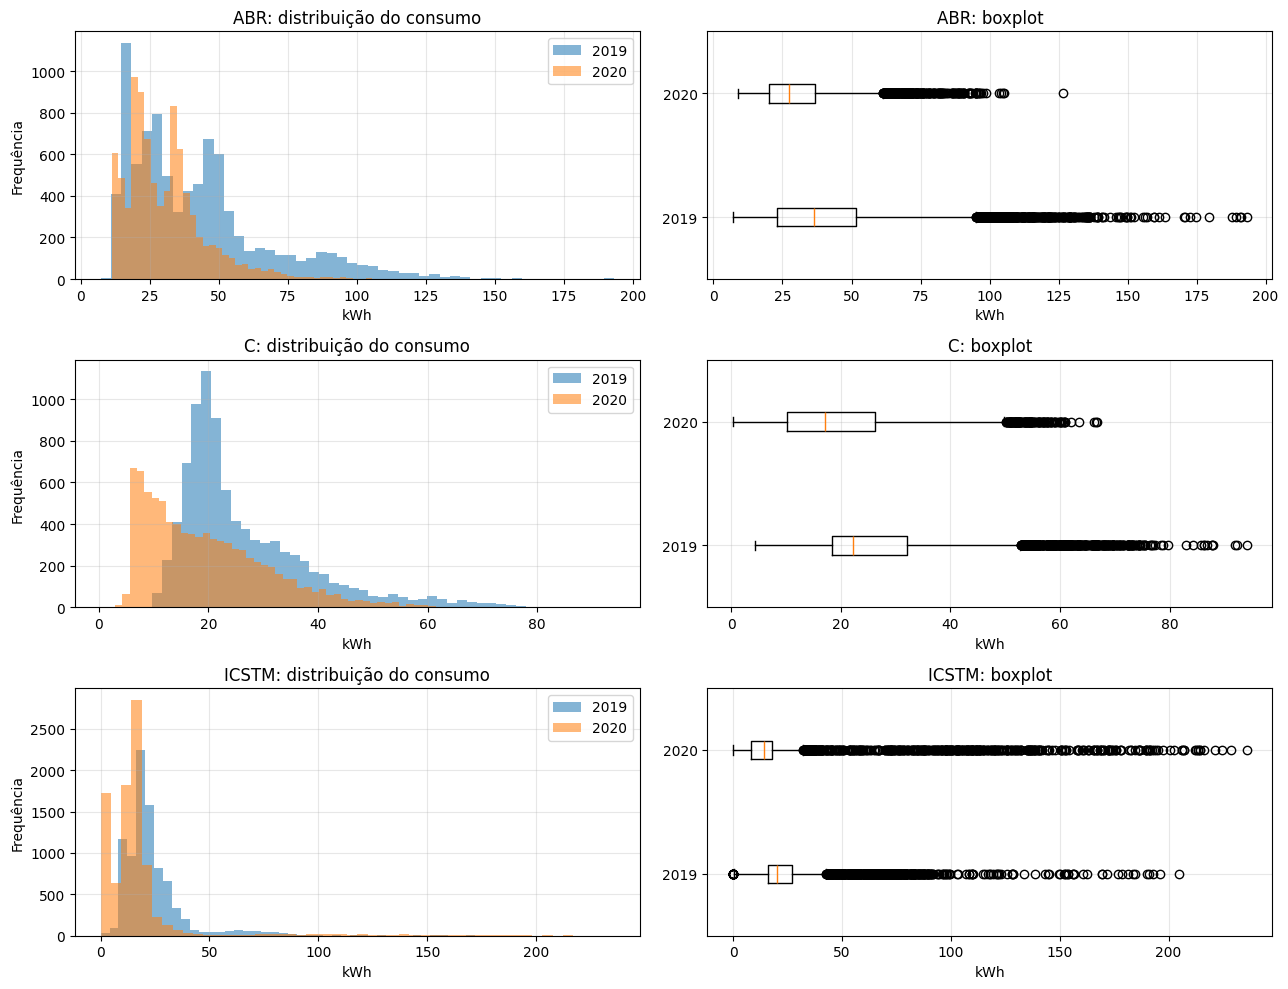

In [4]:
fig, ax = plt.subplots(3, 2, figsize=(13, 10))
for i, ed in enumerate(EDIFICIOS):
    g = d[d.edificio == ed]
    for a in anos:
        ax[i, 0].hist(g[g.ano == a]["consumo"], bins=50, alpha=0.55, label=str(a))
    ax[i, 0].set(title=f"{ed}: distribuição do consumo", xlabel="kWh", ylabel="Frequência"); ax[i, 0].legend()
    ax[i, 1].boxplot([g[g.ano == a]["consumo"] for a in anos], orientation="horizontal", tick_labels=[str(a) for a in anos])
    ax[i, 1].set(title=f"{ed}: boxplot", xlabel="kWh")
plt.tight_layout(); plt.show()

## 4.1.4. Valores em falta ou inconsistentes
Valores em falta, valores inconsistentes (≤ 0), duplicados, regularidade da frequência e outliers (regra do IQR).

In [5]:
linhas = []
for (ed, a), g in d.groupby(["edificio", "ano"]):
    x = g["consumo"]
    q1, q3 = x.quantile([0.25, 0.75]); iqr = q3 - q1
    n_out = ((x > q3 + 1.5*iqr) | (x < q1 - 1.5*iqr)).sum()
    linhas.append({
        "edificio": ed, "ano": a,
        "em falta": int(x.isna().sum()),
        "<= 0": int((x <= 0).sum()),
        "duplicados": int(x.index.duplicated().sum()),
        "saltos ≠ 1h": int((g["hora_ano"].diff().dropna() != 1).sum()),
        "outliers IQR": int(n_out),
        "% outliers": round(100 * n_out / len(x), 1),
    })
pd.DataFrame(linhas).set_index(["edificio", "ano"])

em falta  <= 0  duplicados  saltos ≠ 1h  outliers IQR  \
edificio ano                                                           
ABR      2019         0     0           0            0           477   
         2020         0     0           0            0           326   
C        2019         0     0           0            0           460   
         2020         0     0           0            0           137   
ICSTM    2019         0    17           0            0           643   
         2020         0   652           0            0           546   

               % outliers  
edificio ano               
ABR      2019         5.4  
         2020         3.7  
C        2019         5.3  
         2020         1.6  
ICSTM    2019         7.3  
         2020         6.2

In [6]:
# Onde estão os valores <= 0? (consumo nulo real ou falha de medição?)
z = d[d["consumo"] <= 0]
if len(z) == 0:
    print("Nenhum valor <= 0.")
for ed, g in z.groupby("edificio"):
    print(f"=== {ed}: {len(g)} horas com consumo <= 0")
    print(g.groupby(["ano", "mes"]).size().rename("horas").unstack(0).fillna(0).astype(int).T.to_string())
    grupo = (g.index.to_series().diff() != pd.Timedelta("1h")).cumsum()
    blocos = sorted(g.groupby(grupo.values).apply(lambda b: (b.index.min(), b.index.max(), len(b))), key=lambda t: -t[2])[:5]
    print("Maiores sequências contínuas:")
    for ini, fim, n in blocos:
        print(f"   {ini} -> {fim} ({n} h)")
    print()

=== ICSTM: 669 horas com consumo <= 0
mes   1   2   3    4    5   6   7   8    9   10  11
ano                                                
2019   0   2   0    0    3   5   4   3    0   0   0
2020  40  37  97  101  112  42  43  42  107  24   7
Maiores sequências contínuas:
   2020-09-01 00:00:00 -> 2020-09-03 15:00:00 (64 h)
   2020-08-13 02:00:00 -> 2020-08-13 11:00:00 (10 h)
   2020-03-20 09:00:00 -> 2020-03-20 16:00:00 (8 h)
   2020-03-23 09:00:00 -> 2020-03-23 16:00:00 (8 h)
   2020-03-24 09:00:00 -> 2020-03-24 16:00:00 (8 h)



## 4.1.5. Evolução do consumo ao longo do tempo

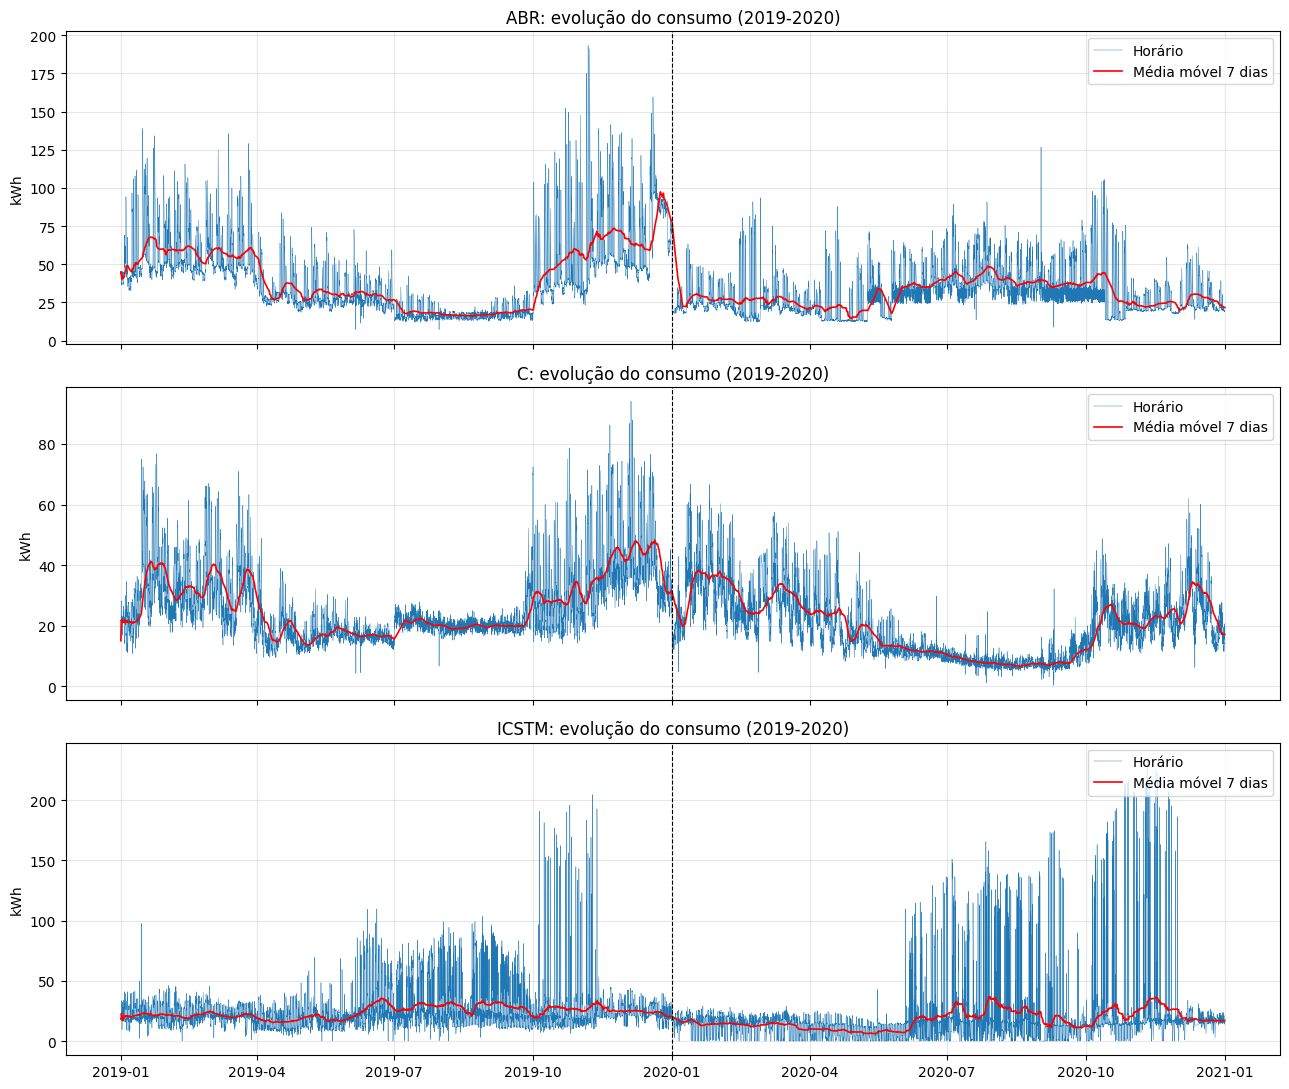

In [7]:
fig, ax = plt.subplots(3, 1, figsize=(13, 11), sharex=True)
for i, ed in enumerate(EDIFICIOS):
    s = d[d.edificio == ed]["consumo"]
    ax[i].plot(s, lw=0.3, label="Horário")
    ax[i].plot(s.rolling(24*7, min_periods=1).mean(), color="red", lw=1.2, label="Média móvel 7 dias")
    ax[i].axvline(pd.Timestamp("2020-01-01"), color="k", ls="--", lw=0.8)
    ax[i].set(title=f"{ed}: evolução do consumo (2019-2020)", ylabel="kWh"); ax[i].legend(loc="upper right")
plt.tight_layout(); plt.show()

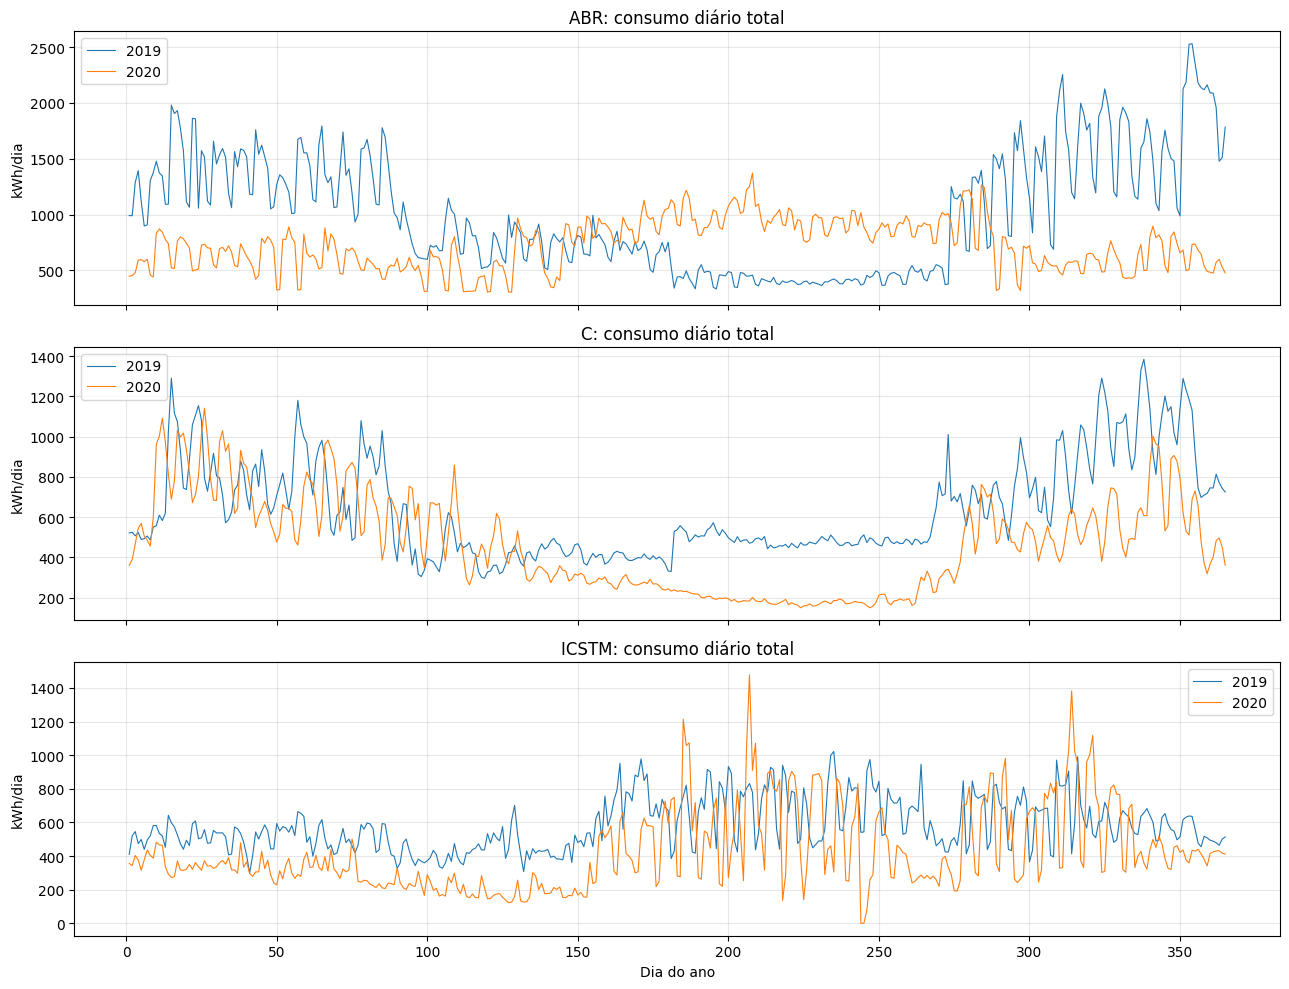

In [8]:
# 2019 vs 2020 sobrepostos (consumo diário total, por dia do ano)
fig, ax = plt.subplots(3, 1, figsize=(13, 10), sharex=True)
for i, ed in enumerate(EDIFICIOS):
    for a in anos:
        x = d[(d.edificio == ed) & (d.ano == a)]["consumo"].resample("D").sum(min_count=1).dropna()
        ax[i].plot(d[(d.edificio == ed) & (d.ano == a)]["dia_ano"].groupby(level=0).first().loc[x.index].values, x.values, lw=0.8, label=str(a))
    ax[i].set(title=f"{ed}: consumo diário total", ylabel="kWh/dia"); ax[i].legend()
ax[-1].set_xlabel("Dia do ano")
plt.tight_layout(); plt.show()

## 4.1.6. Padrões diários, semanais e sazonais

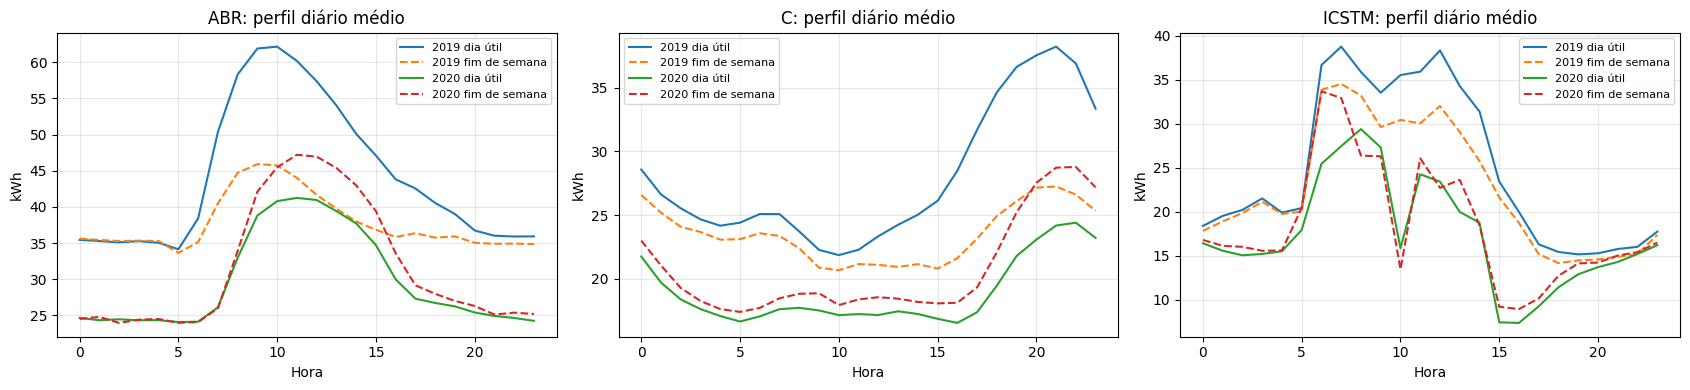

In [9]:
# Perfil diário médio: dia útil vs fim de semana
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
for i, ed in enumerate(EDIFICIOS):
    for a in anos:
        p = d[(d.edificio == ed) & (d.ano == a)].groupby(["hora", "fim_semana"])["consumo"].mean().unstack()
        ax[i].plot(p.index, p[False], label=f"{a} dia útil")
        ax[i].plot(p.index, p[True], ls="--", label=f"{a} fim de semana")
    ax[i].set(title=f"{ed}: perfil diário médio", xlabel="Hora", ylabel="kWh"); ax[i].legend(fontsize=8)
plt.tight_layout(); plt.show()

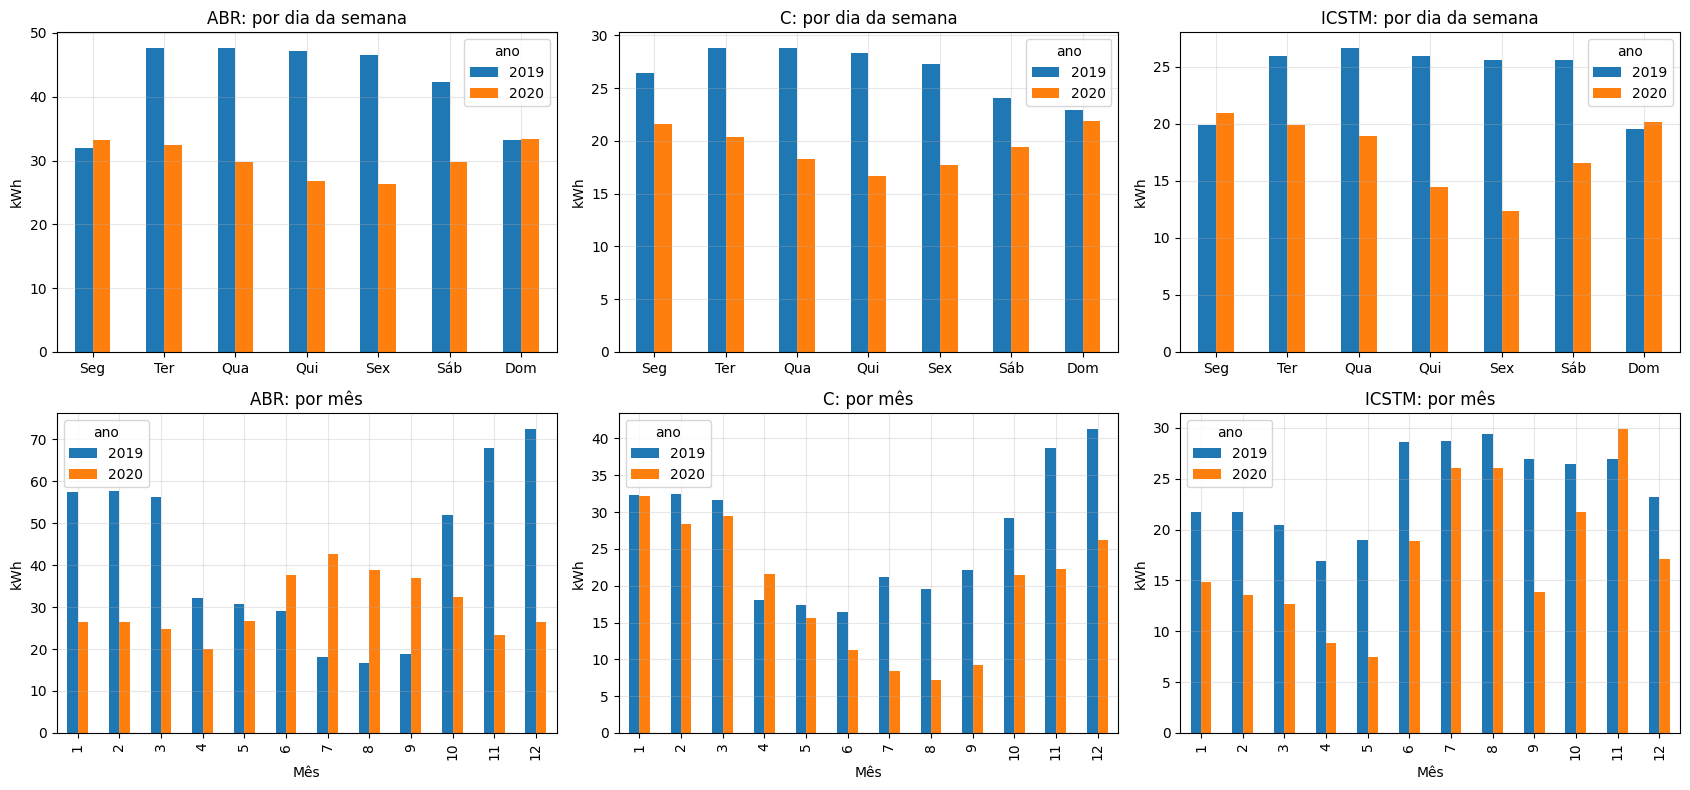

In [10]:
# Padrão semanal e sazonal (mensal)
fig, ax = plt.subplots(2, 3, figsize=(17, 8))
for i, ed in enumerate(EDIFICIOS):
    g = d[d.edificio == ed]
    g.groupby(["dia_semana", "ano"])["consumo"].mean().unstack().plot(kind="bar", ax=ax[0, i], title=f"{ed}: por dia da semana")
    ax[0, i].set_xticklabels(DIAS, rotation=0); ax[0, i].set(xlabel="", ylabel="kWh")
    g.groupby(["mes", "ano"])["consumo"].mean().unstack().plot(kind="bar", ax=ax[1, i], title=f"{ed}: por mês")
    ax[1, i].set(xlabel="Mês", ylabel="kWh")
plt.tight_layout(); plt.show()

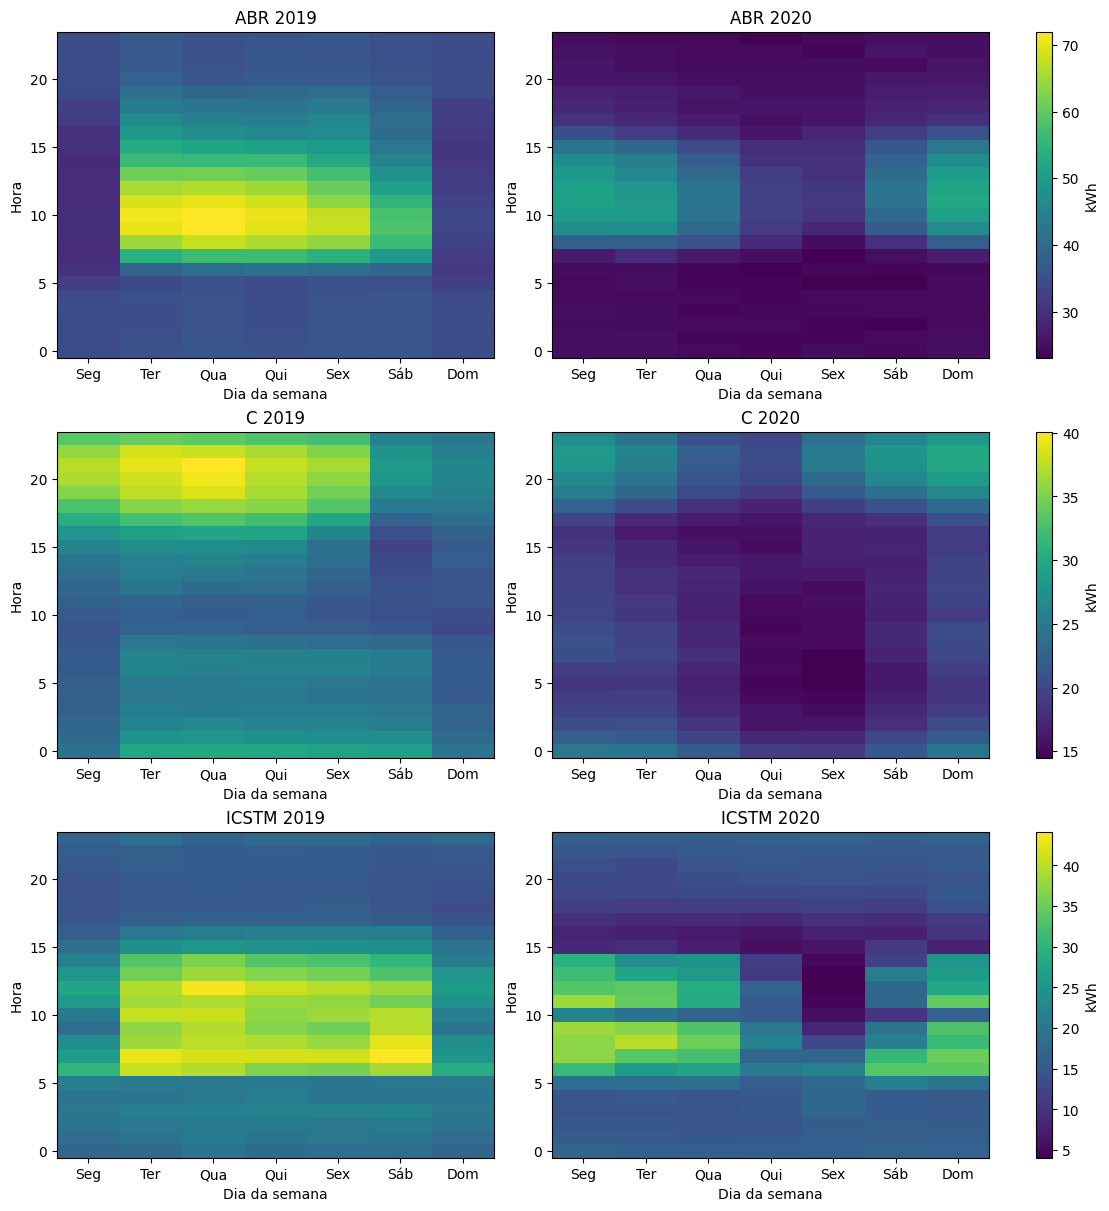

In [11]:
# Heatmaps hora x dia da semana (uma linha por edifício, uma coluna por ano)
fig, ax = plt.subplots(3, 2, figsize=(11, 12), constrained_layout=True)
for i, ed in enumerate(EDIFICIOS):
    pv = {a: d[(d.edificio == ed) & (d.ano == a)].pivot_table(index="hora", columns="dia_semana", values="consumo", aggfunc="mean") for a in anos}
    vmin = min(p.values.min() for p in pv.values()); vmax = max(p.values.max() for p in pv.values())
    for j, a in enumerate(anos):
        im = ax[i, j].imshow(pv[a], aspect="auto", cmap="viridis", origin="lower", vmin=vmin, vmax=vmax)
        ax[i, j].set(title=f"{ed} {a}", xlabel="Dia da semana", ylabel="Hora")
        ax[i, j].set_xticks(range(7)); ax[i, j].set_xticklabels(DIAS); ax[i, j].grid(False)
    fig.colorbar(im, ax=ax[i, :], label="kWh")
plt.show()

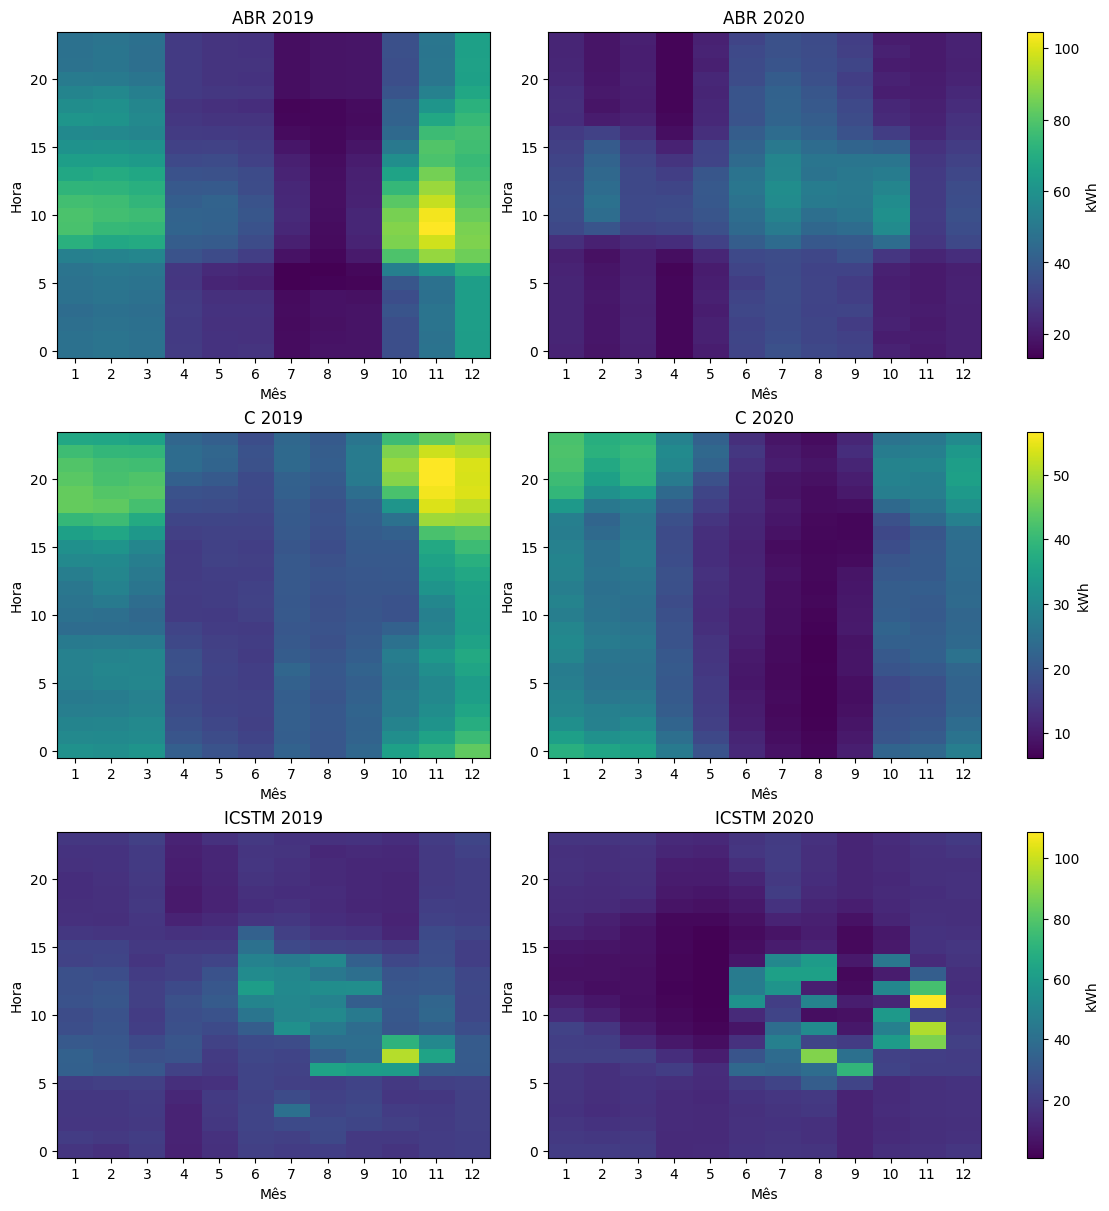

In [12]:
# Heatmaps hora x mês: como o ciclo diário muda ao longo do ano
fig, ax = plt.subplots(3, 2, figsize=(11, 12), constrained_layout=True)
for i, ed in enumerate(EDIFICIOS):
    pv = {a: d[(d.edificio == ed) & (d.ano == a)].pivot_table(index="hora", columns="mes", values="consumo", aggfunc="mean") for a in anos}
    vmin = min(p.values.min() for p in pv.values()); vmax = max(p.values.max() for p in pv.values())
    for j, a in enumerate(anos):
        im = ax[i, j].imshow(pv[a], aspect="auto", cmap="viridis", origin="lower", vmin=vmin, vmax=vmax)
        ax[i, j].set(title=f"{ed} {a}", xlabel="Mês", ylabel="Hora")
        ax[i, j].set_xticks(range(12)); ax[i, j].set_xticklabels(range(1, 13)); ax[i, j].grid(False)
    fig.colorbar(im, ax=ax[i, :], label="kWh")
plt.show()

In [13]:
# Autocorrelação: confirma ciclos diários (24h) e semanais (168h)
rotulos = {
    1:   "hora anterior",
    2:   "2 h antes",
    3:   "3 h antes",
    12:  "12 h antes",
    24:  "mesma hora, dia anterior",
    48:  "mesma hora, 2 dias antes",
    168: "mesma hora, semana anterior",
}
ac = {(ed, a): {rot: round(d[(d.edificio == ed) & (d.ano == a)]["consumo"].autocorr(l), 3)
                for l, rot in rotulos.items()}
      for ed in EDIFICIOS for a in anos}
pd.DataFrame(ac).T

hora anterior  2 h antes  3 h antes  12 h antes  \
ABR   2019          0.974      0.921      0.857       0.487   
      2020          0.919      0.831      0.708       0.135   
C     2019          0.965      0.907      0.839       0.485   
      2020          0.965      0.928      0.888       0.753   
ICSTM 2019          0.662      0.465      0.317      -0.161   
      2020          0.498      0.368      0.165      -0.001   

            mesma hora, dia anterior  mesma hora, 2 dias antes  \
ABR   2019                     0.833                     0.687   
      2020                     0.767                     0.573   
C     2019                     0.874                     0.767   
      2020                     0.873                     0.758   
ICSTM 2019                     0.678                     0.522   
      2020                     0.653                     0.414   

            mesma hora, semana anterior  
ABR   2019                        0.858  
      2020                        0.753  
C     2019                        0.760  
      2020                        0.831  
ICSTM 2019                        0.679  
      2020                        0.600

## 4.1.7. Períodos de consumo elevado ou reduzido

In [14]:
diario = d.groupby(["edificio", "ano"])["consumo"].resample("D").sum(min_count=1).dropna()
for ed in EDIFICIOS:
    for a in anos:
        dd = diario.loc[(ed, a)]
        g = d[(d.edificio == ed) & (d.ano == a)]
        mh = g.groupby("hora")["consumo"].mean(); mm = g.groupby("mes")["consumo"].mean()
        print(f"===== {ed} {a} =====")
        print("Dias de maior consumo :", ", ".join(f"{i.date()} ({v:.0f})" for i, v in dd.nlargest(5).items()))
        print("Dias de menor consumo :", ", ".join(f"{i.date()} ({v:.0f})" for i, v in dd.nsmallest(5).items()))
        print(f"Hora de pico médio: {mh.idxmax()}h | hora de mínimo médio: {mh.idxmin()}h")
        print(f"Mês de maior consumo: {mm.idxmax()} | mês de menor consumo: {mm.idxmin()}\n")

===== ABR 2019 =====
Dias de maior consumo : 2019-12-20 (2530), 2019-12-19 (2526), 2019-12-21 (2355), 2019-11-07 (2254), 2019-12-18 (2186)
Dias de menor consumo : 2019-07-15 (335), 2019-07-08 (336), 2019-07-01 (342), 2019-07-22 (348), 2019-07-14 (349)
Hora de pico médio: 10h | hora de mínimo médio: 5h
Mês de maior consumo: 12 | mês de menor consumo: 8

===== ABR 2020 =====
Dias de maior consumo : 2020-07-27 (1373), 2020-10-11 (1265), 2020-07-26 (1250), 2020-10-12 (1243), 2020-07-25 (1222)
Dias de menor consumo : 2020-05-08 (305), 2020-04-30 (306), 2020-05-07 (308), 2020-04-22 (309), 2020-04-09 (312)
Hora de pico médio: 11h | hora de mínimo médio: 5h
Mês de maior consumo: 7 | mês de menor consumo: 4

===== C 2019 =====
Dias de maior consumo : 2019-12-04 (1384), 2019-12-03 (1331), 2019-11-20 (1290), 2019-01-15 (1290), 2019-12-17 (1289)
Dias de menor consumo : 2019-04-29 (296), 2019-04-28 (301), 2019-04-08 (304), 2019-04-07 (316), 2019-05-04 (318)
Hora de pico médio: 21h | hora de mínimo 

In [15]:
# Variação 2020 vs 2019
m = d.groupby(["edificio", "ano"])["consumo"].mean().unstack()
m["variação %"] = (100 * (m[2020] / m[2019] - 1)).round(1)
m.round(2)

ano,2019,2020,variação %
edificio,,,
ABR,42.37,30.25,-28.6
C,26.67,19.42,-27.2
ICSTM,24.19,17.61,-27.2


## 4.1.8. Comparação entre edifícios (complemento ao guião)
Perfil diário normalizado pela média do próprio edifício/ano (permite comparar a forma do consumo, independentemente da escala).

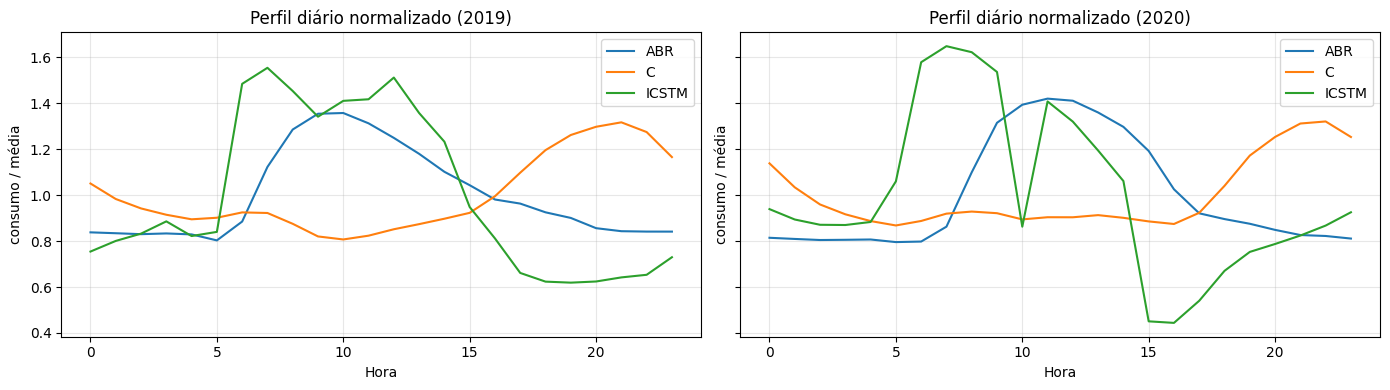

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for j, a in enumerate(anos):
    for ed in EDIFICIOS:
        g = d[(d.edificio == ed) & (d.ano == a)]
        p = g.groupby("hora")["consumo"].mean() / g["consumo"].mean()
        ax[j].plot(p.index, p.values, label=ed)
    ax[j].set(title=f"Perfil diário normalizado ({a})", xlabel="Hora", ylabel="consumo / média"); ax[j].legend()
plt.tight_layout(); plt.show()

## 4.1.9. Conclusões da análise exploratória
- **Dados e qualidade:** 52 560 registos horários (3 edifícios × 2 anos × 8760 h), em kWh por hora, sem valores em falta nem datas repetidas. Os zeros existem só no ICSTM (17 em 2019 e 652 em 2020), com o maior bloco a durar 64 h. As séries elétricas são distintas entre edifícios e entre anos (correlações baixas), por isso tratam-se como medições independentes.
- **Distribuição:** assimétrica à direita, com muitas horas de consumo baixo e uma cauda de picos (até cerca de 190 kWh no ABR e 235 kWh no ICSTM).
- **Mudança de regime em 2020:** o consumo médio desceu entre 27 % e 29 % (ABR −28,6 %, C −27,2 %, ICSTM −27,2 %). Não parece ser só efeito da pandemia: o ABR e o ICSTM já estavam mais baixos em janeiro e fevereiro de 2020, e o C só desce a partir de abril. A sazonalidade do ABR inverte-se em 2020 (mais consumo no verão que no inverno).
- **Sazonalidade:** em 2019 o ABR e o C consomem mais nos meses frios (de outubro a março) e menos no verão. O ICSTM é diferente, com picos grandes entre junho e novembro e consumo mais plano de janeiro a maio.
- **Padrão diário:** o pico do ABR é por volta das 10h–11h, o do C às 21h–22h e o do ICSTM às 7h (com um segundo pico por volta das 12h). O mapa de calor hora × mês mostra que o ciclo diário é mais intenso nos meses frios no ABR e no C (de manhã no ABR, ao fim do dia no C) e nos meses de junho a novembro no ICSTM.
- **Padrão semanal:** em 2019 o C tem o padrão habitual (dias úteis acima do fim de semana), enquanto o ABR e o ICSTM têm segundas-feiras tão baixas como os domingos e sábados altos. Em 2020 o consumo ao fim de semana é igual ou superior ao de meio da semana nos três edifícios. Como os feriados confirmam o alinhamento das datas em 2019, estes padrões são provavelmente comportamento real dos edifícios.
- **Períodos de consumo elevado e reduzido:** os dias de maior consumo do ABR e do C em 2019 são de novembro e dezembro, e os de menor consumo do ABR estão em julho. No C, os dias mais baixos de 2019 são 28 e 29 de abril (Páscoa ortodoxa). Em 2020 o C é mais baixo em agosto e setembro.
- **Ciclos e previsibilidade:** a autocorrelação é muito alta com a hora anterior no ABR e no C (0,92 a 0,97) e bem menor no ICSTM (0,50 a 0,66). Há ciclo diário forte (0,65 a 0,87 com a mesma hora do dia anterior). O ICSTM é o edifício mais difícil de prever.
- **Implicações para a modelação:** o consumo recente (hora e dia anteriores) e a hora do dia são informativos, e a diferença entre 2019 e 2020 obriga a pensar com cuidado na divisão treino/validação/teste.

---
# 4.2. Preparação dos dados

## 4.2.1. Verificação e ordenação temporal dos registos
Cada edifício passa a ter **uma série única, 2019 + 2020**, ordenada no tempo. Verifica-se que a ordem é crescente e que não há instantes repetidos.

In [17]:
dp = d.copy().sort_index(kind="stable")      # ordenação temporal (a ordem dentro de cada hora não importa)
linhas = []
for ed in EDIFICIOS:
    s = dp[dp.edificio == ed]["consumo"]
    linhas.append({"edifício": ed, "registos": len(s),
                   "ordem crescente": s.index.is_monotonic_increasing,
                   "sem datas repetidas": s.index.is_unique,
                   "início": s.index.min(), "fim": s.index.max()})
pd.DataFrame(linhas).set_index("edifício")

,registos,ordem crescente,sem datas repetidas,início,fim
edifício,,,,,
ABR,17520,True,True,2019-01-01,2020-12-31 23:00:00
C,17520,True,True,2019-01-01,2020-12-31 23:00:00
ICSTM,17520,True,True,2019-01-01,2020-12-31 23:00:00


## 4.2.2. Tratamento de valores em falta ou inválidos
Não há valores em falta. Há **zeros** no ICSTM (consumo ≤ 0), que num edifício em funcionamento são pouco plausíveis. Analisa-se o comprimento dos blocos de zeros consecutivos e define-se um tratamento.

**Proposta de tratamento**:
- blocos de zeros **curtos** (até `LIMITE_H` horas) são tratados como falhas de registo e substituídos por **interpolação linear**;
- blocos **longos** são mantidos como estão (podem ser paragens reais) e ficam assinalados na coluna `zero_longo`;
- o valor original fica guardado em `consumo_original`.

In [18]:
LIMITE_H = 3          # blocos de zeros com até 3 h consecutivas são interpolados

dp["consumo_original"] = dp["consumo"]
partes = []
for ed in EDIFICIOS:
    g = dp[dp.edificio == ed].copy()
    z = g["consumo_original"] <= 0
    bloco = (z != z.shift()).cumsum()                    # identifica cada sequência de zeros
    tamanho = z.groupby(bloco).transform("size")        # comprimento da sequência a que cada zero pertence
    g["zero_curto"] = z & (tamanho <= LIMITE_H)
    g["zero_longo"] = z & (tamanho > LIMITE_H)
    g["consumo"] = g["consumo_original"].mask(g["zero_curto"]).interpolate(method="time")
    partes.append(g)
dp = pd.concat(partes).sort_index(kind="stable")

resumo = dp.groupby(["edificio", "ano"]).agg(zeros_total=("consumo_original", lambda s: int((s <= 0).sum())),
                                              interpolados=("zero_curto", "sum"),
                                              mantidos=("zero_longo", "sum"))
resumo

zeros_total  interpolados  mantidos
edificio ano                                      
ABR      2019            0             0         0
         2020            0             0         0
C        2019            0             0         0
         2020            0             0         0
ICSTM    2019           17             9         8
         2020          652           239       413

In [19]:
# Efeito nas estatísticas do ICSTM (antes vs depois do tratamento)
g = dp[dp.edificio == "ICSTM"]
pd.DataFrame({"antes": g.groupby("ano")["consumo_original"].agg(["mean", "min"]).stack(),
              "depois": g.groupby("ano")["consumo"].agg(["mean", "min"]).stack()}).round(2).T

ano      2019        2020     
         mean  min   mean  min
antes   24.19  0.0  17.61  0.0
depois  24.20  0.0  17.74  0.0

## 4.2.3. Identificação de valores atípicos
Usou-se o IQR sobre toda a série, que tende a marcar os picos normais do ciclo diário. Aqui compara-se cada valor com o **padrão típico da sua hora e do seu dia da semana** (média por edifício, ano, hora e dia da semana) e mede-se o desvio em unidades de **desvio padrão**. Consideram-se atípicos os valores a mais de `LIMIAR_DP` desvios padrão da média.

Os valores atípicos são **apenas assinalados** (coluna `atipico`), não removidos: num problema de previsão fazem parte do comportamento real, e removê-los do conjunto de teste tornaria a avaliação demasiado otimista.

In [20]:
LIMIAR_DP = 3
chave = [dp["edificio"], dp["ano"], dp["hora"], dp["dia_semana"]]
media = dp.groupby(chave)["consumo"].transform("mean")
desvio_padrao = dp.groupby(chave)["consumo"].transform("std")
dp["desvio_z"] = (dp["consumo"] - media) / desvio_padrao.replace(0, np.nan)
dp["atipico"] = dp["desvio_z"].abs() > LIMIAR_DP

t = dp.groupby(["edificio", "ano"])["atipico"].agg(["sum", "mean"])
t.columns = ["nº atípicos", "% atípicos"]; t["% atípicos"] = (100 * t["% atípicos"]).round(1)
t

nº atípicos  % atípicos
edificio ano                          
ABR      2019          112         1.3
         2020           17         0.2
C        2019           16         0.2
         2020            9         0.1
ICSTM    2019          125         1.4
         2020          173         2.0

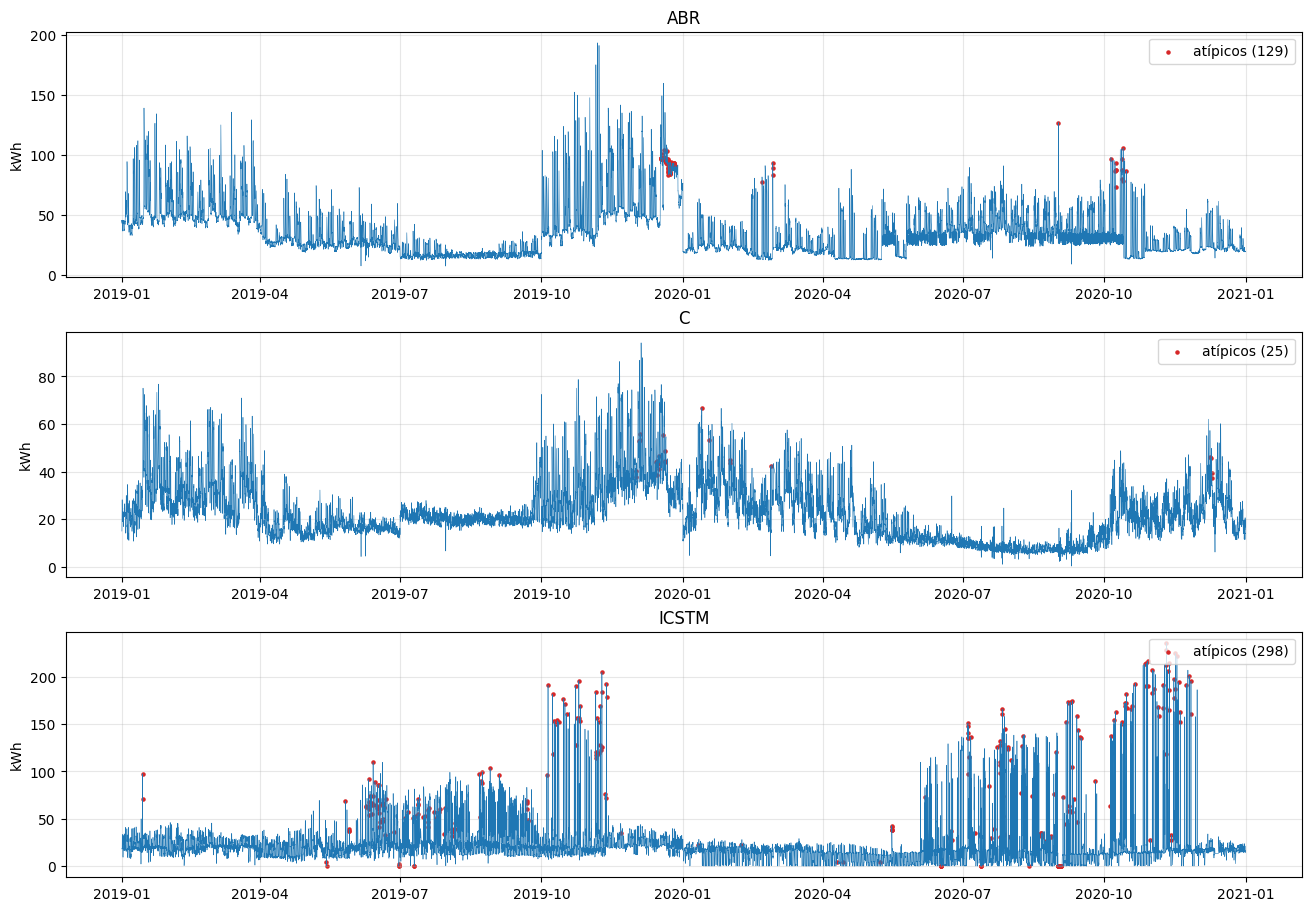

In [21]:
fig, ax = plt.subplots(3, 1, figsize=(13, 9), constrained_layout=True)
for i, ed in enumerate(EDIFICIOS):
    g = dp[dp.edificio == ed]
    ax[i].plot(g.index, g["consumo"], lw=0.4, color="tab:blue")
    at = g[g["atipico"]]
    ax[i].scatter(at.index, at["consumo"], s=5, color="tab:red", label=f"atípicos ({len(at)})")
    ax[i].set(title=ed, ylabel="kWh"); ax[i].legend(loc="upper right")
plt.show()

**Leitura:** o ABR e o C têm muito poucos atípicos (no máximo 1,3 % das horas). No ABR quase todos estão em dezembro de 2019, o mês de maior consumo. No **ICSTM** são mais frequentes (1,4 % em 2019 e 2,0 % em 2020), quase todos picos acima do esperado e sobretudo entre junho e novembro. A mediana dos atípicos do ICSTM é cerca de 67 kWh/h (chega a 236), quando a mediana do edifício é cerca de 17 kWh/h. Não parecem erros isolados, mas períodos em que o edifício funciona de forma diferente, e por isso não se removem. O desvio padrão é afetado pelos próprios picos, por isso no ICSTM marca menos horas do que um método mais robusto marcaria. É um edifício difícil de prever, e na análise de erros convém ver estes períodos em separado.

## 4.2.4. Verificação da periodicidade dos registos
O intervalo entre registos consecutivos deve ser sempre 1 hora, inclusive na passagem de 2019 para 2020.

In [22]:
linhas = []
for ed in EDIFICIOS:
    g = dp[dp.edificio == ed]
    s = g["consumo"]
    dif = g.groupby("ano")["hora_ano"].diff().dropna()          # horas entre registos consecutivos (dentro de cada ano)
    linhas.append({"edifício": ed,
                   "intervalos distintos": dif.nunique(),
                   "intervalo (h)": int(dif.iloc[0]),
                   "saltos ≠ 1h": int((dif != 1).sum()),
                   "2019 → 2020 contínuo": s[s.index.year == 2019].index.max() + pd.Timedelta("1h") == s[s.index.year == 2020].index.min(),
                   "dias em 2019": s[s.index.year == 2019].index.normalize().nunique(),
                   "dias em 2020": s[s.index.year == 2020].index.normalize().nunique()})
pd.DataFrame(linhas).set_index("edifício")

,intervalos distintos,intervalo (h),saltos ≠ 1h,2019 → 2020 contínuo,dias em 2019,dias em 2020
edifício,,,,,,
ABR,1,1,0,True,365,365
C,1,1,0,True,365,365
ICSTM,1,1,0,True,365,365


- A periodicidade é de **1 hora** em todos os edifícios, sem falhas, e a passagem de 2019 para 2020 é contínua.
- **2020 tem 365 dias em vez de 366** (ano bissexto) por convenção. Fica comparável com 2019 dia a dia (o dia do ano coincide nos dois anos).
- Os ficheiros não indicam fuso horário e não mostram dias de 23 h ou 25 h, por isso não há ajuste de hora de verão/inverno.

## 4.2.5. Criação de variáveis temporais
Inclui a verificação do calendário (que condiciona as variáveis de dia da semana e dia útil), a criação das variáveis e a sua justificação em função do problema de previsão.

### 4.2.5.1. Verificação do calendário (feriados)
Os ficheiros não têm datas, mas o README do dataset indica que os dados vão de 1 de janeiro de 2019 a 31 de dezembro de 2020, e é com essas datas que se reconstrói o calendário (e os dias da semana). Para confirmar o alinhamento, usam-se os **feriados oficiais da Roménia**.

Para cada feriado compara-se o consumo médio diário com a mediana dos 20 dias à volta (razão abaixo de 1 = dia mais baixo que o normal), e repete-se o teste com as datas deslocadas de −3 a +3 dias. Com o alinhamento certo, o valor mais baixo deve estar no deslocamento **0**.

In [23]:
FERIADOS = pd.to_datetime([
    "2019-01-01", "2019-01-02", "2019-01-24", "2019-04-26", "2019-04-28", "2019-04-29", "2019-05-01", "2019-06-01",
    "2019-06-16", "2019-06-17", "2019-08-15", "2019-11-30", "2019-12-01", "2019-12-25", "2019-12-26",
    "2020-01-01", "2020-01-02", "2020-01-24", "2020-04-17", "2020-04-19", "2020-04-20", "2020-05-01", "2020-06-01",
    "2020-06-07", "2020-06-08", "2020-08-15", "2020-11-30", "2020-12-01", "2020-12-25", "2020-12-26"])   # feriados da Roménia

def razao_feriados(dia, feriados, deslocamentos=range(-3, 4)):
    r = {}
    for k in deslocamentos:
        v = []
        for f in feriados:
            t = f + pd.Timedelta(days=k)
            if t in dia.index:
                v.append(dia[t] / dia[t - pd.Timedelta(days=10): t + pd.Timedelta(days=10)].median())
        r[k] = np.mean(v)
    return r

linhas = {}
for ed in EDIFICIOS:
    for a in anos:
        dia = dp[(dp.edificio == ed) & (dp.ano == a)]["consumo"].resample("D").mean().dropna()
        linhas[(ed, a)] = razao_feriados(dia, FERIADOS[FERIADOS.year == a])
tabela_feriados = pd.DataFrame(linhas).T
tabela_feriados.columns.name = "deslocamento (dias)"
tabela_feriados.round(2)

deslocamento (dias)    -3    -2    -1     0     1     2     3
ABR   2019           0.99  1.02  0.95  0.84  0.89  0.91  0.94
      2020           0.92  0.95  0.96  0.92  1.06  1.08  1.00
C     2019           0.99  0.97  0.93  0.93  0.95  0.98  1.00
      2020           0.95  0.94  0.94  0.97  1.00  1.06  1.01
ICSTM 2019           0.99  1.02  1.03  0.95  1.00  1.02  1.02
      2020           0.95  1.02  1.12  1.08  1.04  1.19  1.04

**Leitura:**
- **2019:** o consumo mais baixo nos feriados está no deslocamento 0 nos três edifícios (ABR 0,84, C 0,93, ICSTM 0,95; no C empata com −1), sobretudo no ABR, onde o consumo cai cerca de 16 %. Isto confirma que as datas de 2019 estão alinhadas com o calendário.
- **2020:** o teste é menos claro. O consumo diminuiu em geral e a diferença entre feriados e dias normais quase desaparece (ABR 0,92 no 0, igual ao de −3; no C e no ICSTM não há queda clara). Não confirma nem contraria o alinhamento, por isso mantêm-se as datas do readme (1 de janeiro a 31 de dezembro, ano de 365 dias).
- O padrão semanal diferente do habitual (segunda-feira baixa no ABR e no ICSTM em 2019, fim de semana alto em 2020) é por isso provavelmente **comportamento real dos edifícios**, e não um erro de datas. Com os dados disponíveis não é possível confirmar a causa.

### 4.2.5.2. Variáveis criadas
Cada linha representa **a hora a prever**; as variáveis só usam informação **anterior** a essa hora (sem informação futura).

- **Hora do dia:** em vez do número da hora (0 a 23), usa-se a **posição da hora num relógio de 24 horas**, dada por duas coordenadas (`hora_relogio_x` e `hora_relogio_y`, calculadas com cosseno e seno). Assim a hora 23 fica perto da hora 0.
- **Consumo em horas anteriores:** `consumo_hora_anterior` (hora anterior), e `consumo_dia_anterior` (mesma hora do dia anterior), calculados dentro de cada edifício com o consumo já tratado.

In [24]:
# Posição da hora num relógio de 24 h (x = cosseno, y = seno)
dp["hora_relogio_y"] = np.sin(2 * np.pi * dp["hora"] / 24);       dp["hora_relogio_x"] = np.cos(2 * np.pi * dp["hora"] / 24)

# Consumos anteriores (dentro de cada edifício; as linhas são consecutivas, com 1 h entre registos, e 29 fev 2020 não existe)
for k, nome in {1: "consumo_hora_anterior", 24: "consumo_dia_anterior"}.items():
    dp[nome] = dp.groupby("edificio")["consumo"].shift(k)

FEATURES_BASE = ["hora_relogio_y", "hora_relogio_x", "consumo_hora_anterior", "consumo_dia_anterior"]

print("Linhas sem consumo anterior (início da série de cada edifício):", dp["consumo_dia_anterior"].isna().sum() // len(EDIFICIOS), "por edifício")
dp[dp.edificio == "ABR"][["consumo"] + FEATURES_BASE].iloc[[0, 1, 24, 25, 26]].round(3)

Linhas sem consumo anterior (início da série de cada edifício): 24 por edifício


,consumo,hora_relogio_y,hora_relogio_x,consumo_hora_anterior,consumo_dia_anterior
2019-01-01 00:00:00,44.630,0.000,1.000,NaN,NaN
2019-01-01 01:00:00,45.302,0.259,0.966,44.630,NaN
2019-01-02 00:00:00,44.569,0.000,1.000,44.459,44.630
2019-01-02 01:00:00,44.960,0.259,0.966,44.569,45.302
2019-01-02 02:00:00,43.812,0.500,0.866,44.960,43.848


### 4.2.5.3. Justificação das variáveis em função do problema
O objetivo é prever o consumo da hora seguinte, e a análise exploratória mostrou o que ajuda:

| Variável | Justificação |
|---|---|
| `consumo_hora_anterior` (hora anterior) | O consumo varia pouco de uma hora para a seguinte: autocorrelação de 0,92 a 0,97 no ABR e no C. No ICSTM é menor (0,50 a 0,66), com mais saltos. |
| `consumo_dia_anterior` (mesma hora do dia anterior) | Ciclo diário forte: autocorrelação de 0,65 a 0,87 em todas as séries. |
| `consumo_semana_anterior` (**não usado**) | A autocorrelação com a mesma hora da semana anterior é alta (0,60 a 0,86), mas num teste preliminar com um modelo linear o ganho foi pequeno (cerca de 1 % a 5 % no erro). Retirou-se para simplificar, e pode ser reavaliado nos modelos finais. |
| `hora_relogio_y`, `hora_relogio_x` | O perfil ao longo do dia é muito marcado e muda por edifício (picos por volta das 10h–11h no ABR, 21h–22h no C e 7h no ICSTM). |

In [25]:
# Correlação de Pearson entre o consumo e cada variável candidata (só relação linear)
cand = ["consumo_hora_anterior", "consumo_dia_anterior", "hora_relogio_y", "hora_relogio_x"]
x = dp.dropna(subset=["consumo_dia_anterior"])
pd.DataFrame({ed: x[x.edificio == ed][["consumo"] + cand].astype(float).corr()["consumo"].drop("consumo") for ed in EDIFICIOS}).round(2)

,ABR,C,ICSTM
consumo_hora_anterior,0.96,0.97,0.56
consumo_dia_anterior,0.83,0.88,0.67
hora_relogio_y,0.03,-0.18,0.21
hora_relogio_x,-0.30,0.18,-0.18


## 4.2.6. Guardar em CSV

In [26]:
colunas = ["edificio", "consumo"] + FEATURES_BASE + ["consumo_original", "zero_longo", "atipico"]
dados_prontos = dp[colunas]

pasta = RAIZ / "dataset" / "final"
pasta.mkdir(exist_ok=True)
dados_prontos.to_csv(pasta / "electrical_demand.csv", index_label="data_hora")
print(dados_prontos.groupby("edificio").size().to_dict(), "| total:", len(dados_prontos))

{'ABR': 17520, 'C': 17520, 'ICSTM': 17520} | total: 52560


## 4.2.7. Resumo da preparação dos dados
- **Ordenação e periodicidade:** séries ordenadas e com 1 h entre registos, 2019 + 2020 (2020 com 365 dias, falta 1 dia).
- **Valores em falta:** não existem. **Zeros do ICSTM:** blocos até 3 h interpolados; blocos mais longos mantidos e assinalados (`zero_longo`).
- **Atípicos:** horas a mais de 3 desvios padrão da média da mesma hora e dia da semana, assinaladas (`atipico`) e não removidas.
- **Calendário:** datas reconstruídas a partir do readme (1 de janeiro de 2019 a 31 de dezembro de 2020, com 2020 tratado como ano de 365 dias). Os feriados romenos confirmam o alinhamento em 2019, e em 2020 o teste é inconclusivo (secção 4.2.5.1).
- **Variáveis base:** `hora_relogio_y`, `hora_relogio_x`, `consumo_hora_anterior`, `consumo_dia_anterior`. Não se usam variáveis de calendário (dia da semana, mês, dia útil).
- **Próximo passo (4.3):** divisão cronológica treino/validação/teste, escalonamento ajustado só no treino e tratamento das primeiras 24 h de cada edifício (1 de janeiro de 2019): ficam na tabela, mas sem `consumo_dia_anterior`, por isso não são usadas como hora a prever, só como histórico para as horas seguintes.